In [1]:

import nltk
import pandas as pd

# Download the sentiment dataset
nltk.download('movie_reviews')

from nltk.corpus import movie_reviews

# Collect reviews and their labels
reviews = []

for fileid in movie_reviews.fileids():
    text = movie_reviews.raw(fileid)
    sentiment = movie_reviews.categories(fileid)[0]

    reviews.append({
        'Review': text,
        'Sentiment': sentiment
    })

# Create a DataFrame
df = pd.DataFrame(reviews)

# Display the dataset
print("Dataset shape:", df.shape)
print("\nSentiment distribution:")
print(df['Sentiment'].value_counts())

df.head()


[nltk_data] Downloading package movie_reviews to /root/nltk_data...
[nltk_data]   Unzipping corpora/movie_reviews.zip.


Dataset shape: (2000, 2)

Sentiment distribution:
Sentiment
neg    1000
pos    1000
Name: count, dtype: int64


,Review,Sentiment
0,"plot : two teen couples go to a church party ,...",neg
1,the happy bastard's quick movie review \ndamn ...,neg
2,it is movies like these that make a jaded movi...,neg
3,""" quest for camelot "" is warner bros . ' firs...",neg
4,synopsis : a mentally unstable man undergoing ...,neg


In [2]:

!pip install nltk

import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [3]:

import re
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stop-word removal and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return ' '.join(cleaned_tokens)

# Test the function on one review
print("Original review:")
print(df['Review'][0][:300])

print("\nCleaned review:")
print(preprocess_text(df['Review'][0])[:300])


Original review:
plot : two teen couples go to a church party , drink and then drive . 
they get into an accident . 
one of the guys dies , but his girlfriend continues to see him in her life , and has nightmares . 
what's the deal ? 
watch the movie and " sorta " find out . . . 
critique : a mind-fuck movie for the

Cleaned review:
plot two teen couple go church party drink drive get accident one guy dy girlfriend continues see life nightmare deal watch movie sorta find critique mind fuck movie teen generation touch cool idea present bad package make review even harder one write since generally applaud film attempt break mold 


In [4]:

df['Cleaned_Review'] = df['Review'].apply(preprocess_text)

print("Preprocessing completed!")
print(df[['Review', 'Cleaned_Review', 'Sentiment']].head())


Preprocessing completed!
                                              Review  \
0  plot : two teen couples go to a church party ,...   
1  the happy bastard's quick movie review \ndamn ...   
2  it is movies like these that make a jaded movi...   
3   " quest for camelot " is warner bros . ' firs...   
4  synopsis : a mentally unstable man undergoing ...   

                                      Cleaned_Review Sentiment  
0  plot two teen couple go church party drink dri...       neg  
1  happy bastard quick movie review damn bug got ...       neg  
2  movie like make jaded movie viewer thankful in...       neg  
3  quest camelot warner bros first feature length...       neg  
4  synopsis mentally unstable man undergoing psyc...       neg  


In [5]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Initialize the TF-IDF vectorizer
tfidf = TfidfVectorizer(max_features=5000)

# Convert cleaned reviews into numerical features
X = tfidf.fit_transform(df['Cleaned_Review'])

# Target labels
y = df['Sentiment']

print("TF-IDF conversion completed!")
print("Number of reviews:", X.shape[0])
print("Number of features:", X.shape[1])
print("TF-IDF matrix shape:", X.shape)


TF-IDF conversion completed!
Number of reviews: 2000
Number of features: 5000
TF-IDF matrix shape: (2000, 5000)


In [6]:

# Display the first 10 vocabulary words
print("Sample vocabulary:")
print(list(tfidf.vocabulary_.keys())[:10])

# Display TF-IDF values for the first review
print("\nTF-IDF values for the first review:")
print(X[0].toarray()[0][:20])


Sample vocabulary:
['plot', 'two', 'teen', 'couple', 'go', 'church', 'party', 'drink', 'drive', 'get']

TF-IDF values for the first review:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [7]:

from sklearn.model_selection import train_test_split

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Data splitting completed!")
print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Training labels:", y_train.shape[0])
print("Testing labels:", y_test.shape[0])


Data splitting completed!
Training samples: 1600
Testing samples: 400
Training labels: 1600
Testing labels: 400


In [8]:

from sklearn.naive_bayes import MultinomialNB

# Create the Naive Bayes classifier
model = MultinomialNB()

# Train the model using training data
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [9]:

# Predict sentiment for the test reviews
y_pred = model.predict(X_test)

print("Predictions generated successfully!")
print("First 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())


Predictions generated successfully!
First 10 actual labels:
['neg', 'neg', 'pos', 'neg', 'neg', 'pos', 'pos', 'neg', 'neg', 'pos']

First 10 predicted labels:
['neg', 'neg', 'pos', 'pos', 'neg', 'pos', 'pos', 'neg', 'neg', 'pos']


In [10]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("=" * 35)
print(f"Accuracy: {accuracy * 100:.2f}%")

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Negative', 'Positive']
))


MODEL EVALUATION RESULTS
Accuracy: 80.75%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.79      0.84      0.81       200
    Positive       0.83      0.78      0.80       200

    accuracy                           0.81       400
   macro avg       0.81      0.81      0.81       400
weighted avg       0.81      0.81      0.81       400



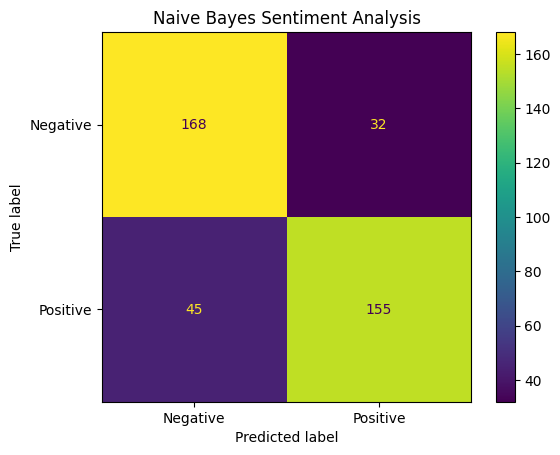

In [11]:

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=['neg', 'pos'])

# Display the matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Negative', 'Positive']
)

disp.plot()
plt.title("Naive Bayes Sentiment Analysis")
plt.show()


In [12]:

# Create new reviews for testing
new_reviews = [
    "This movie was amazing and I really enjoyed it",
    "The movie was boring and a complete waste of time",
    "Excellent acting and a wonderful story",
    "I hated this movie because it was terrible"
]

# Apply the same preprocessing used for training
cleaned_reviews = [preprocess_text(review) for review in new_reviews]

# Convert the reviews using the existing TF-IDF vectorizer
new_reviews_tfidf = tfidf.transform(cleaned_reviews)

# Predict sentiment
predictions = model.predict(new_reviews_tfidf)

# Display results
for review, sentiment in zip(new_reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", sentiment.upper())
    print("-" * 50)


Review: This movie was amazing and I really enjoyed it
Predicted Sentiment: POS
--------------------------------------------------
Review: The movie was boring and a complete waste of time
Predicted Sentiment: NEG
--------------------------------------------------
Review: Excellent acting and a wonderful story
Predicted Sentiment: POS
--------------------------------------------------
Review: I hated this movie because it was terrible
Predicted Sentiment: NEG
--------------------------------------------------


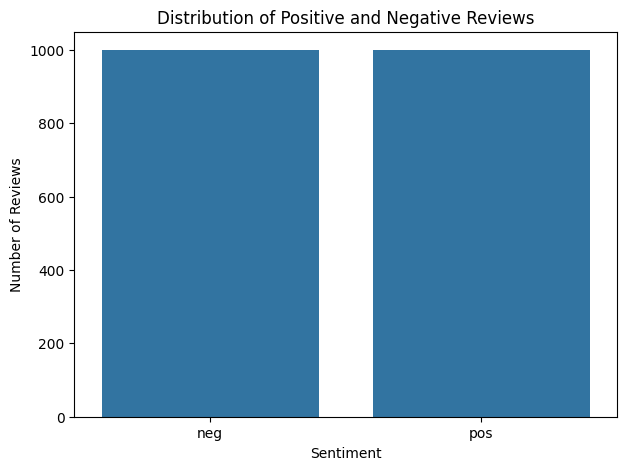

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count positive and negative reviews
sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(7, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


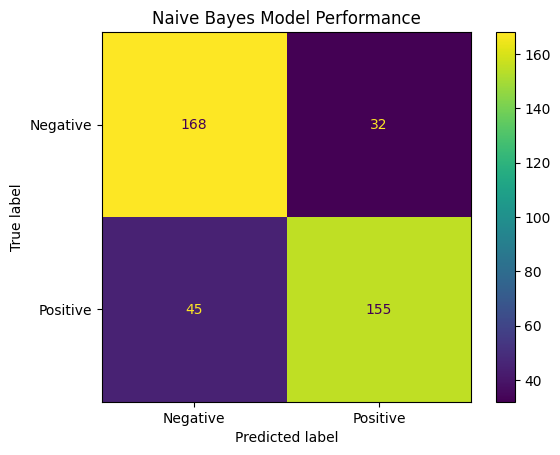

In [14]:

from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=['neg', 'pos'],
    display_labels=['Negative', 'Positive']
)

plt.title("Naive Bayes Model Performance")
plt.show()
